# PCA and Kalman statistical arbitrage

Compare a daily equity residual-reversal signal under fixed and adaptive factor exposures, then test whether risk-based sizing helps after costs. Five variants share the same universes, signals and schedule. Results include unsuccessful variants rather than selecting the best curve.

The experiment configuration is in `config.json`. Prices are downloaded directly from Yahoo Finance and retained as a checksummed local snapshot.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from equity_stat_arb.pipeline import run
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/equity_stat_arb").exists())
manifest = run(ROOT)
metrics = pd.read_csv(ROOT / "artifacts/metrics.csv")
daily = pd.read_parquet(ROOT / "artifacts/daily_returns.parquet")
calibration = pd.read_csv(ROOT / "artifacts/calibration.csv")

Evaluating technology


Evaluating financials


Evaluating energy


Evaluating uk_equities


   universe                         variant  days  sharpe    cagr  max_drawdown
 technology                     PCA / equal   250 -1.7599 -0.2333       -0.2715
 technology            Fixed Kalman / equal   250 -1.7599 -0.2333       -0.2715
 technology       Calibrated Kalman / equal   250 -1.8429 -0.2548       -0.2814
 technology      Fixed Kalman / inverse vol   250 -2.1146 -0.2594       -0.2833
 technology Calibrated Kalman / inverse vol   250 -1.9749 -0.2526       -0.2766
 financials                     PCA / equal   250  1.1096  0.0747       -0.0492
 financials            Fixed Kalman / equal   250  1.1096  0.0747       -0.0492
 financials       Calibrated Kalman / equal   250  0.7648  0.0488       -0.0529
 financials      Fixed Kalman / inverse vol   250  1.0268  0.0695       -0.0493
 financials Calibrated Kalman / inverse vol   250  0.7596  0.0489       -0.0512
     energy                     PCA / equal   250 -0.7396 -0.0821       -0.1762
     energy            Fixed Kalman / eq

## Data

Four separately evaluated universes: US technology, financials, energy, and UK equities. Each has 15 stocks. These are current hand-picked names, not reconstructed historical index constituents, so survivorship and universe-selection bias remain.

Adjusted daily closes cover 2017–2025. No price interpolation is used: observations are aligned on complete dates within each universe. All portfolios are evaluated from the same calendar start after the model and signal warmup. US and UK exchange calendars have different trading-day counts.

Current provider symbols identify the companies throughout their downloaded history. For example, BNY's historical prices use its current symbol ([company announcement](https://www.bny.com/corporate/global/en/about-us/newsroom/press-release/bny-announces-planned-change-of-stock-ticker-symbol-to-bny-130465.html)). A missing history causes an explicit failure rather than silently replacing a stock.

In [2]:
display(pd.DataFrame(manifest["snapshot"]["files"])[["universe", "observations", "first_date", "last_date", "minimum_raw_coverage"]])
print("Common evaluation start:", manifest["evaluation_start"])
print("Universe sizes:", {name: len(names) for name, names in manifest["config"]["data"]["universes"].items()})

,universe,observations,first_date,last_date,minimum_raw_coverage
0,technology,2262,2017-01-03,2025-12-31,1.00000
1,financials,2262,2017-01-03,2025-12-31,1.00000
2,energy,2262,2017-01-03,2025-12-31,1.00000
3,uk_equities,2270,2017-01-03,2025-12-31,0.99956


Common evaluation start: 2018-07-09
Universe sizes: {'technology': 15, 'financials': 15, 'energy': 15, 'uk_equities': 15}


## Models

Correlation PCA is estimated by eigendecomposition of the standardized-return covariance matrix. The smallest factor set explaining 55% of training variance is kept. Each 126-day window uses only past observations and the basis refits every 10 days.

$$r^{std}_{i,t}=\alpha_{i,t}+\beta_{i,t}^{\top}f_t+\epsilon_{i,t}.$$

PCA uses fixed loadings within each block. Kalman variants track the intercept and loadings. The residual saved for the signal is the innovation **before** the filter update. Coefficients reset at each PCA refit instead of mixing coordinates from changing bases.

## Calibration

The first 84 days of each past window fit scaling, PCA and residual variance. The last 42 days score sequential Gaussian predictive likelihood. The grid contains seven process-noise scales and three observation-noise multipliers: **21 combinations**, evaluated in parallel. A single pair is selected for the universe, not separately optimized for each stock. The production model then fits the full 126-day window. Neither portfolio profits nor future test data enter this choice.

## Signals and allocation

The ranking signal is the negative sum of five residual returns divided by 20-day residual volatility. After 252 residual observations of warmup, three stocks per side are selected every 20 days. Equal sizing assigns 50% of NAV per side. Inverse-volatility sizing uses raw stock returns from the preceding 20 days and caps each target position at 25% of NAV.

Orders take effect one observation after the signal. Stock quantities drift between scheduled rebalances; trading costs are charged on changes from those drifted holdings. Neutrality and caps hold at rebalances only. Cash earns no interest, and borrow fees/availability and market impact are absent.

## Evaluation

Development ends in 2022, validation covers 2023–2024, and the final historical reporting period is 2025. Specifications were fixed before this implementation's first 2025 evaluation. However, overlapping market histories had been explored earlier, so this should not be described as a completely untouched research holdout.

No variant was selected using the final period, and all five are reported. Main metrics exclude the initial no-trading warmup. Each reporting period recomputes wealth and drawdown from its own daily returns.

DEVELOPMENT


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
energy,0.043,-0.023,0.016,-0.040,0.021
financials,0.016,0.082,0.102,0.165,0.131
technology,-0.050,-0.160,-0.092,-0.202,-0.154
uk_equities,0.254,0.294,0.231,0.270,0.240


VALIDATION


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
energy,-0.239,-0.311,-0.101,-0.179,-0.200
financials,-1.002,-0.884,-1.019,-0.898,-1.002
technology,-0.534,-0.677,-0.443,-0.609,-0.443
uk_equities,0.934,0.613,1.304,1.013,1.304


HOLDOUT


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
energy,-0.732,-0.711,-0.869,-0.804,-0.740
financials,0.765,0.760,1.110,1.027,1.110
technology,-1.843,-1.975,-1.760,-2.115,-1.760
uk_equities,-0.824,-0.990,-0.739,-0.886,-0.739


ALL


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
energy,-0.111,-0.171,-0.121,-0.171,-0.120
financials,-0.166,-0.089,-0.071,-0.004,-0.050
technology,-0.472,-0.577,-0.446,-0.594,-0.481
uk_equities,0.282,0.214,0.364,0.307,0.369


,universe,variant,days,cagr,max_drawdown,average_daily_turnover
10,technology,PCA / equal,250,-0.2333,-0.2715,0.0838
26,technology,Fixed Kalman / equal,250,-0.2333,-0.2715,0.0838
42,technology,Calibrated Kalman / equal,250,-0.2548,-0.2814,0.0836
58,technology,Fixed Kalman / inverse vol,250,-0.2594,-0.2833,0.0867
74,technology,Calibrated Kalman / inverse vol,250,-0.2526,-0.2766,0.0865
90,financials,PCA / equal,250,0.0747,-0.0492,0.0787
106,financials,Fixed Kalman / equal,250,0.0747,-0.0492,0.0787
122,financials,Calibrated Kalman / equal,250,0.0488,-0.0529,0.0787
138,financials,Fixed Kalman / inverse vol,250,0.0695,-0.0493,0.0817
154,financials,Calibrated Kalman / inverse vol,250,0.0489,-0.0512,0.0820


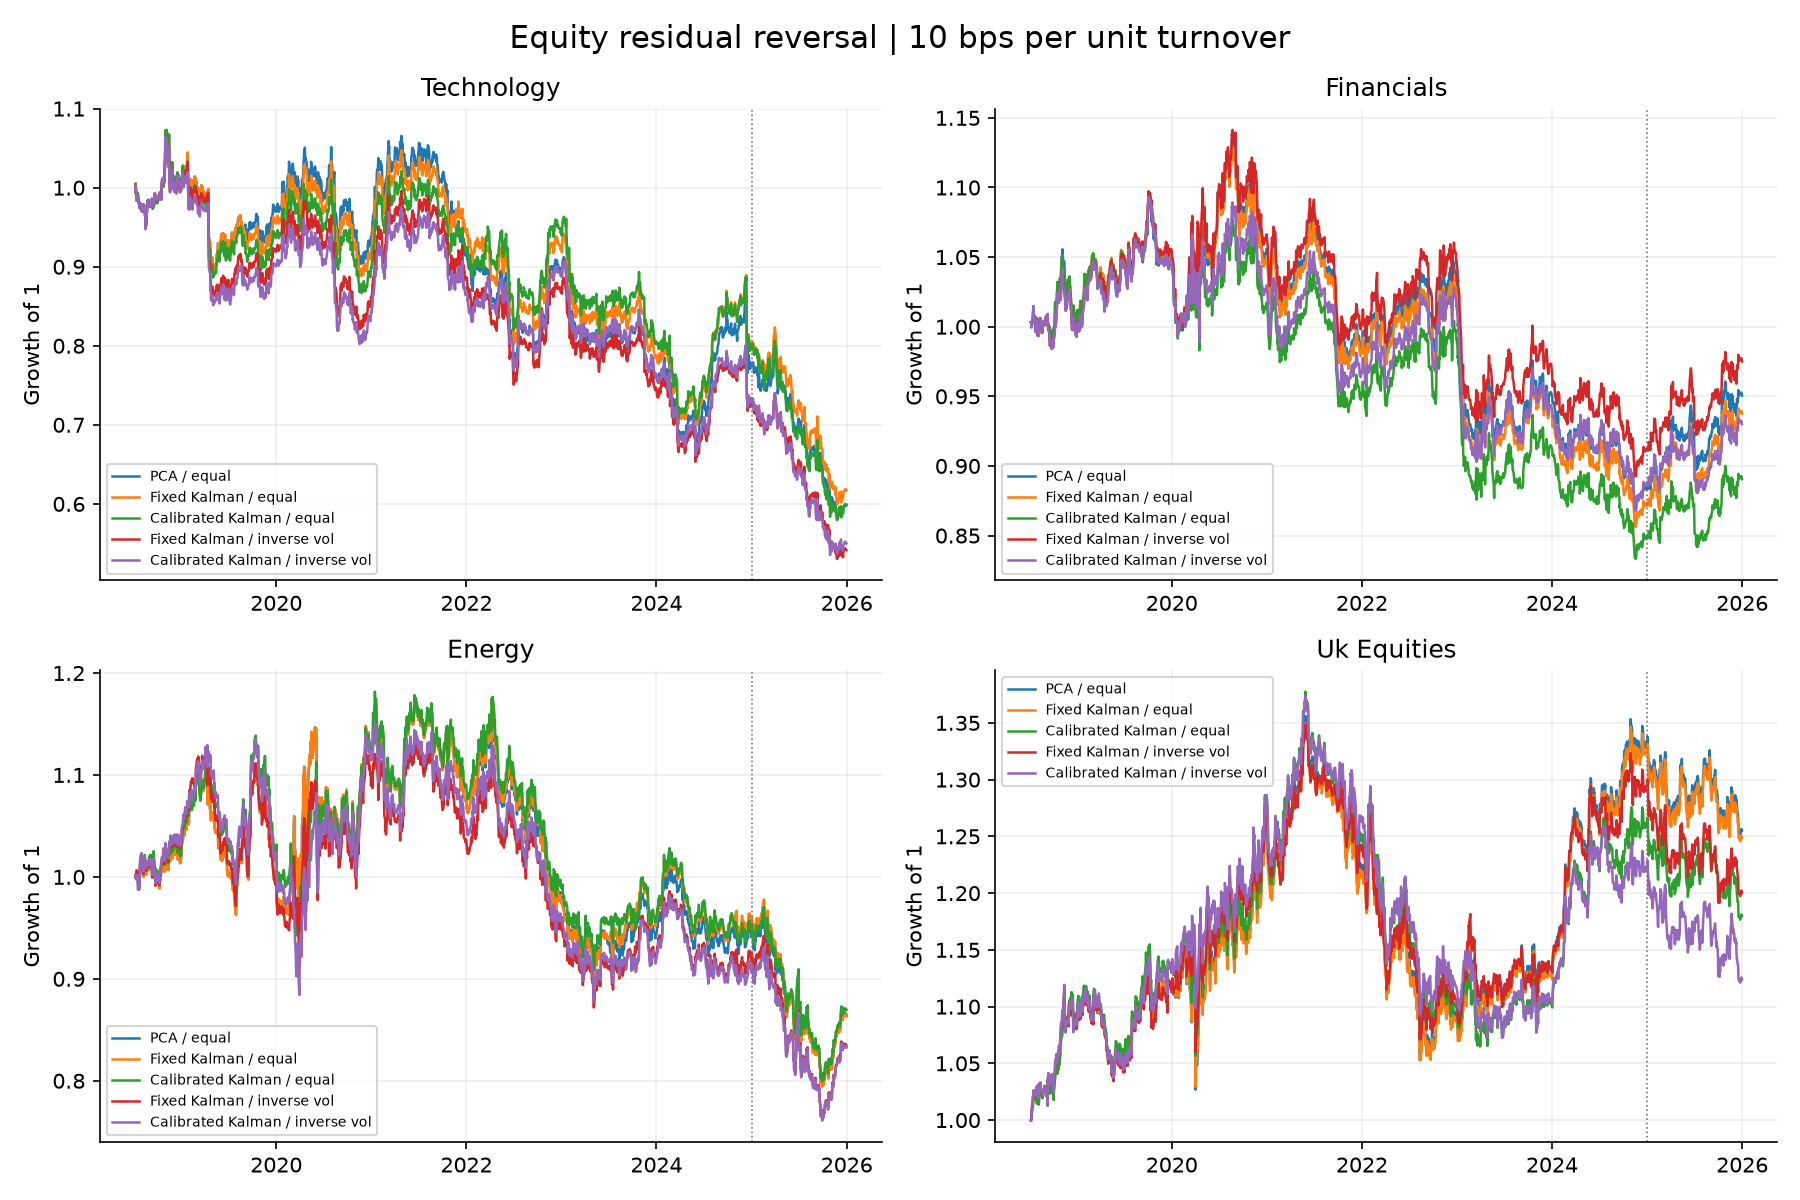

In [3]:
at_10 = metrics[metrics.cost_bps == 10]
for period in ["development", "validation", "holdout", "all"]:
    print(period.upper())
    display(at_10[at_10.period == period].pivot(index="universe", columns="variant", values="sharpe").round(3))
display(at_10[at_10.period == "holdout"][["universe", "variant", "days", "cagr", "max_drawdown", "average_daily_turnover"]].round(4))
display(Image(filename=str(ROOT / "artifacts/overview.png")))

## Cost sensitivity and calibration choices

Costs are per unit of absolute traded weight, not per round trip. Holding drift is included when calculating the next rebalance turnover. The strategy uses a daily-close execution proxy, not a simulation of actual opening fills.

In [4]:
for universe in ["technology", "financials", "energy", "uk_equities"]:
    print(universe.upper(), "— full evaluation Sharpe by cost")
    subset = metrics[(metrics.universe == universe) & (metrics.period == "all")]
    display(subset.pivot(index="cost_bps", columns="variant", values="sharpe").round(3))
print("Number of selected Q/R pairs across rolling refits:")
display(calibration.groupby(["universe", "q", "r"]).size().rename("refits").to_frame())

TECHNOLOGY — full evaluation Sharpe by cost


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,-0.313,-0.410,-0.285,-0.427,-0.320
5,-0.393,-0.494,-0.365,-0.511,-0.401
10,-0.472,-0.577,-0.446,-0.594,-0.481
20,-0.628,-0.740,-0.604,-0.759,-0.639


FINANCIALS — full evaluation Sharpe by cost


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.103,0.184,0.191,0.262,0.216
5,-0.032,0.048,0.060,0.129,0.083
10,-0.166,-0.089,-0.071,-0.004,-0.050
20,-0.432,-0.360,-0.330,-0.267,-0.313


ENERGY — full evaluation Sharpe by cost


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.080,0.027,0.070,0.028,0.072
5,-0.016,-0.072,-0.025,-0.071,-0.024
10,-0.111,-0.171,-0.121,-0.171,-0.120
20,-0.300,-0.368,-0.310,-0.368,-0.309


UK_EQUITIES — full evaluation Sharpe by cost


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.503,0.438,0.586,0.531,0.588
5,0.393,0.326,0.475,0.419,0.479
10,0.282,0.214,0.364,0.307,0.369
20,0.062,-0.010,0.143,0.083,0.150


Number of selected Q/R pairs across rolling refits:


refits
universe    q        r          
energy      0.000000 0.5       4
                     1.0      11
                     2.0       9
            0.000001 1.0       2
            0.000010 1.0      11
                     2.0       3
            0.000100 0.5      10
                     1.0      65
                     2.0      17
            0.001000 0.5      13
                     1.0      55
                     2.0       7
            0.010000 1.0       2
                     2.0       2
            0.100000 2.0       3
financials  0.000000 1.0       3
                     2.0       9
            0.000001 1.0       1
                     2.0       2
            0.000010 1.0      10
                     2.0       2
            0.000100 0.5      16
                     1.0      49
                     2.0      21
            0.001000 0.5      16
                     1.0      64
                     2.0      12
            0.010000 1.0       3
                     2.0       2
            0.100000 1.0       1
                     2.0       3
technology  0.000000 1.0      14
                     2.0       5
            0.000001 1.0       1
            0.000010 1.0       4
                     2.0       3
            0.000100 0.5       3
                     1.0      48
                     2.0       9
            0.001000 0.5       2
                     1.0      66
                     2.0      29
            0.010000 0.5       1
                     1.0      15
                     2.0      14
uk_equities 0.000000 1.0       6
                     2.0       3
            0.000010 1.0       3
                     2.0       1
            0.000100 0.5       6
                     1.0      29
                     2.0      15
            0.001000 0.5      10
                     1.0      89
                     2.0      30
            0.010000 0.5       1
                     1.0      18
                     2.0       2
            0.100000 2.0       2

## Notes

The daily residual-reversal specification does not establish a consistent net edge. Most full-period Sharpes are negative; the UK panel's modest positive full-period result reverses in the final year. Financials are positive in 2025 but do not show strong full-period evidence. Calibration and inverse-volatility sizing do not reliably improve performance.

A one-year final slice is short. The small hand-picked universes, missing point-in-time membership, daily execution proxy and omitted shorting costs further limit the conclusions. The purpose is to make the model, accounting and evaluation inspectable, not to claim a deployable trading strategy.

Tests cover fixed-PCA recovery at zero Kalman process noise, batched versus individual filtering, absence of future-data effects, risk caps, signal lag, share drift and cost accounting. There is no Robust PCA, C++ implementation, stationarity/FDR screening or continuous factor-neutral constraint in this study.

Run `python -m equity_stat_arb.pipeline` to rebuild the analysis and `python -m pytest -q` for the numerical checks. Source code is in `src/equity_stat_arb/`; results and provenance are in `artifacts/`.